In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Agents.StrategySARSA import stratSARSA
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
import numpy as np

In [ ]:
from qDDRLBase import qbase
from qBaseSARSA import qbaseSARSA

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

In [ ]:
# Poor environment
env = TwoArmedBandit(rew=1, pun=-1, pA=0.3, pB=0.1)

In [ ]:
quantiles = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
             0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
             0.65, 0.70, 0.75, 0.80, 0.85, 0.90,
             0.95]

In [ ]:
b_pes = np.linspace(0.1, 1., 10)
b_opt = np.linspace(1., 10., 10)
b_ratios = np.zeros((19))
b_ratios[:9] = b_pes[:9]
b_ratios[9:] = b_opt

In [ ]:
def deltaQinf(p0, p1, x):
    return ((p0 * x - (1 - p0)) / (p0 * x + (1 - p0))) - ((p1 * x - (1 - p1)) / (p1 * x + (1 - p1)))

In [ ]:
def Xinf(dQ, beta):
    return 1 / (1 + np.exp(beta * (-dQ)))

In [ ]:
dist_xinf0 = np.zeros((len(quantiles)))

In [ ]:
b_dQs0 = deltaQinf(0.3, 0.1, b_ratios)
b_xinf0 = Xinf(b_dQs0, 4)

In [ ]:
for i, q in enumerate(quantiles):
    mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0, 
                     choice_intensities=4, quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf0[i] = q_xinf

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
dist_xinf1 = np.zeros((len(quantiles)))

for i, q in enumerate(quantiles):
    mae = qbaseSARSA(env, nr_reward_bins=36, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0, 
                     choice_intensities=4, quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf1[i] = q_xinf

In [ ]:
dist_xinf2 = np.zeros((len(quantiles)))

for i, q in enumerate(quantiles):
    mae = qbaseSARSA(env, nr_reward_bins=9, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0, 
                     choice_intensities=4, quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf2[i] = q_xinf

Text(0, 0.5, 'final $X_{00}$')

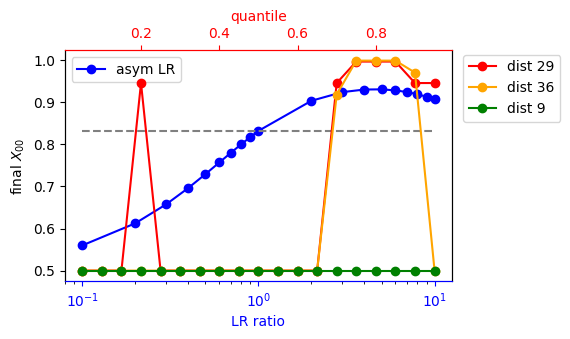

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax2 = ax.twiny()
ax.set_xscale('log')
ax.plot(b_ratios, b_xinf0, '-o', color='blue', label="asym LR")
ax.plot(b_ratios, np.repeat(b_xinf0[9], len(b_ratios)), '--', color='gray')
ax2.plot(quantiles, dist_xinf0, '-o', color='red', label="dist 29")
ax2.plot(quantiles, dist_xinf1, '-o', color='orange', label="dist 36")
ax2.plot(quantiles, dist_xinf2, '-o', color='green', label="dist 9")
ax2.legend(bbox_to_anchor=(1.01, 1.01))
ax.legend(loc='upper left')
ax.set_xlabel("LR ratio", color="blue")
ax2.set_xlabel("quantile", color="red")
ax.xaxis.label.set_color('blue')
ax.tick_params(axis='x', colors='blue')
ax2.xaxis.label.set_color('red')
ax2.tick_params(axis='x', colors='red')
ax.spines['bottom'].set_color('blue')
ax.spines['top'].set_color('red')
ax2.spines['bottom'].set_color('blue')
ax2.spines['top'].set_color('red')
ax.set_ylabel("final "+r'$X_{00}$')

In [ ]:
## Average obtained reward

reward00 = b_xinf0 * (-0.4) + (1-b_xinf0) * (-0.8)
reward9 = dist_xinf2 * (-0.4) + (1 - dist_xinf2) * (-0.8)
reward36 = dist_xinf1 * (-0.4) + (1 - dist_xinf1) * (-0.8)
reward29 = dist_xinf0 * (-0.4) + (1 - dist_xinf0) * (-0.8)

Text(0, 0.5, 'average obtained reward')

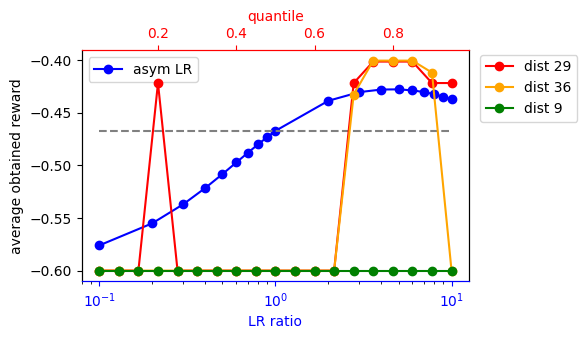

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax2 = ax.twiny()
ax.set_xscale('log')
ax.plot(b_ratios, reward00, '-o', color='blue', label="asym LR")
ax.plot(b_ratios, np.repeat(reward00[9], len(b_ratios)), '--', color='gray')
ax2.plot(quantiles, reward29, '-o', color='red', label="dist 29")
ax2.plot(quantiles, reward36, '-o', color='orange', label="dist 36")
ax2.plot(quantiles, reward9, '-o', color='green', label="dist 9")
ax2.legend(bbox_to_anchor=(1.01, 1.01))
ax.legend(loc='upper left')
ax.set_xlabel("LR ratio", color="blue")
ax2.set_xlabel("quantile", color="red")
ax.xaxis.label.set_color('blue')
ax.tick_params(axis='x', colors='blue')
ax2.xaxis.label.set_color('red')
ax2.tick_params(axis='x', colors='red')
ax.spines['bottom'].set_color('blue')
ax.spines['top'].set_color('red')
ax2.spines['bottom'].set_color('blue')
ax2.spines['top'].set_color('red')
ax.set_ylabel("average obtained reward")

In [ ]:
b_ratios

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  2. ,
        3. ,  4. ,  5. ,  6. ,  7. ,  8. ,  9. , 10. ])

In [ ]:
# Rich environment
env = TwoArmedBandit(rew=1, pun=-1, pA=0.9, pB=0.7)

In [ ]:
dist_xinf = np.zeros((len(quantiles)))
dist_xinf2 = np.zeros((len(quantiles)))

In [ ]:
b_dQs = deltaQinf(0.9, 0.7, b_ratios)
b_xinf = Xinf(b_dQs, 4)

In [ ]:
for i, q in enumerate(quantiles):
    mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0, 
                     choice_intensities=4, quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf[i] = q_xinf

In [ ]:
for i, q in enumerate(quantiles):
    mae = qbaseSARSA(env, nr_reward_bins=36, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0, 
                     choice_intensities=4, quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf2[i] = q_xinf

Text(0, 0.5, 'final $X_{00}$')

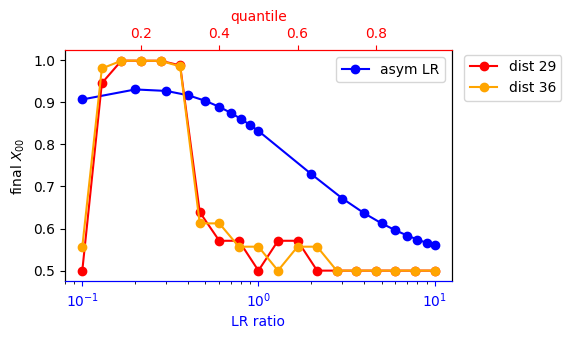

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax2 = ax.twiny()
ax.set_xscale('log')
ax.plot(b_ratios, b_xinf, '-o', color='blue', label="asym LR")
ax2.plot(quantiles, dist_xinf, '-o', color='red', label="dist 29")
ax2.plot(quantiles, dist_xinf2, '-o', color='orange', label="dist 36")
ax2.legend(bbox_to_anchor=(1.3, 1.01))
ax.legend(loc='upper right')
ax.set_xlabel("LR ratio", color="blue")
ax2.set_xlabel("quantile", color="red")
ax.xaxis.label.set_color('blue')
ax.tick_params(axis='x', colors='blue')
ax2.xaxis.label.set_color('red')
ax2.tick_params(axis='x', colors='red')
ax.spines['bottom'].set_color('blue')
ax.spines['top'].set_color('red')
ax2.spines['bottom'].set_color('blue')
ax2.spines['top'].set_color('red')
ax.set_ylabel("final "+r'$X_{00}$')

In [ ]:
dist_xinf

array([0.5       , 0.94568676, 0.99921018, 0.99894923, 0.99894923,
       0.98816985, 0.63909256, 0.57094651, 0.57094651, 0.5       ,
       0.57094646, 0.57094646, 0.5       , 0.5       , 0.5       ,
       0.5       , 0.5       , 0.5       , 0.5       ])

In [ ]:
quantiles

[0.05,
 0.1,
 0.15,
 0.2,
 0.25,
 0.3,
 0.35,
 0.4,
 0.45,
 0.5,
 0.55,
 0.6,
 0.65,
 0.7,
 0.75,
 0.8,
 0.85,
 0.9,
 0.95]

In [ ]:
from pyCRLD.Utils.Trajectories1D import trajectories_1D

In [ ]:
x = ([0], [0, 1, 2], [0])
res = np.linspace(0, 1., 11)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                 learning_rates=0.1, discount_factors=0, 
                 choice_intensities=4, quantile=0.4, use_prefactor=False)

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

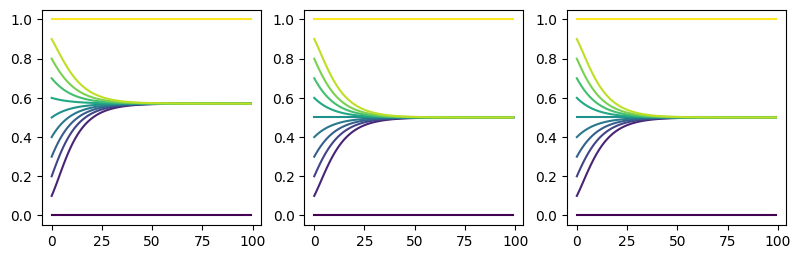

In [ ]:
trajectories_1D(mae, x, res, traj_len=100, NrRandom=1)